# Modelo de Clasificación mediante Regresión Logística

## 1. Introducción

Este notebook estudia si características de la vivienda permiten identificar registros con precariedad en el acceso a servicios básicos. Utiliza los microdatos de vivienda del Censo de Población y Vivienda 2024 del INE Bolivia y reproduce la población definida en `entendimiento de datos.ipynb`. La regresión logística se usa por su adecuación a una clase binaria y porque permite examinar probabilidades y coeficientes. El análisis se centra en este clasificador y no interpreta las asociaciones como efectos causales.

## 2. Definición del problema

La variable objetivo es **`vivienda_precaria`**. Vale **0** cuando una vivienda tiene cero o una carencia y **1** cuando tiene al menos dos. Las cuatro carencias se definen con las respuestas sobre agua, saneamiento, electricidad e internet. La clase solo se asigna si las cuatro dimensiones pueden clasificarse; una respuesta ambigua no se convierte arbitrariamente en acceso o carencia.

En la fórmula, $c$ es la suma de las cuatro carencias (`n_carencias`) y $y$ es `vivienda_precaria`.

$$
y=\begin{cases}
1, & \text{si } c \geq 2,\\
0, & \text{si } c < 2.
\end{cases}
$$

Esta clasificación y el Índice de Precariedad de Servicios (IPS) son **definiciones operativas del proyecto**, no indicadores oficiales publicados por el INE. El IPS describe la proporción observada de viviendas válidas con clase 1; las métricas del modelo evalúan predicciones y tienen otro significado.

## 3. Selección de variables

Se conservan los diez predictores del notebook de modelado original. Proceden de la entidad VIVIENDA y no participan directamente en la fórmula de la clase. El diccionario oficial proporciona sus nombres y categorías; todas se tratan como categóricas, incluso los conteos de habitaciones y dormitorios, para reproducir la codificación inicial. La tabla documenta por qué se usa cada variable.

In [1]:
from pathlib import Path
import gc
import sys
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"font.size":10,"axes.titlesize":13,"figure.dpi":115})
FUENTE = "Fuente: elaboración propia con microdatos del Censo 2024, INE Bolivia."
FUENTE_PRUEBA = "Fuente: elaboración propia. Conjunto de prueba; microdatos del Censo 2024, INE Bolivia."
FUENTE_ENTRENAMIENTO = "Fuente: elaboración propia. Modelo ajustado con entrenamiento; microdatos del Censo 2024, INE Bolivia."
DATA = Path("data")
CSV = DATA / "Vivienda_CPV-2024.csv"
DICCIONARIO = DATA / "Diccionario de variables CPV 2024.xlsx"
assert CSV.is_file() and DICCIONARIO.is_file(), "Los archivos oficiales deben estar en data/."
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

predictoras = ["urbrur", "v01_tipoviv", "v03_pared", "v05_techo", "v06_piso",
               "v11_basura", "v13_habitac", "v14_dormit", "v17_tenencia", "tip_hog"]
fuentes_objetivo = ["v07_aguapro", "v15_servsan", "v16_desague", "v09_energia", "v19e_f"]
columnas_csv = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", nrows=0).columns.tolist()
assert len(columnas_csv) == 48, "El CSV difiere del archivo revisado; comprobar antes de seguir."
assert set(predictoras + fuentes_objetivo).issubset(columnas_csv)

fichas = {}
tabla_dic = pd.read_excel(DICCIONARIO, sheet_name="VIVIENDA", header=None, dtype="string")
descripcion, actual = "", None
for fila in tabla_dic.itertuples(index=False, name=None):
    clave = str(fila[1]).strip() if pd.notna(fila[1]) else ""
    dato = str(fila[2]).strip() if pd.notna(fila[2]) else ""
    if clave == "Etiqueta":
        descripcion = dato
    elif clave == "Nombre":
        actual = dato.lower()
        fichas[actual] = {"descripcion": descripcion, "categorias": {}}
    elif actual is not None and clave not in ("", "Categorías", "Tipo") and pd.notna(fila[2]):
        fichas[actual]["categorias"][clave] = dato
assert all(c in fichas for c in predictoras)

justificacion = {
    "urbrur":"Contexto urbano/rural; no forma parte del objetivo",
    "v01_tipoviv":"Tipo de vivienda",
    "v03_pared":"Material predominante de pared",
    "v05_techo":"Material predominante de techo",
    "v06_piso":"Material predominante de piso",
    "v11_basura":"Práctica de eliminación de basura",
    "v13_habitac":"Número categorizado de habitaciones",
    "v14_dormit":"Número categorizado de dormitorios",
    "v17_tenencia":"Condición de tenencia",
    "tip_hog":"Tipología de hogar documentada",
}
tabla_variables = pd.DataFrame([{
    "Variable": c, "Descripción oficial": fichas[c]["descripcion"],
    "Tipo usado": "Categórica", "Justificación": justificacion[c]
} for c in predictoras])
display(tabla_variables)
print("Nota: las categorías y sus códigos se toman de la hoja VIVIENDA del diccionario oficial.")

Python: 3.14.4 | pandas: 3.0.6 | scikit-learn: 1.9.1


,Variable,Descripción oficial,Tipo usado,Justificación
0,urbrur,Área Urbana - Rural,Categórica,Contexto urbano/rural; no forma parte del obje...
1,v01_tipoviv,1. La vivienda es: (Tipo de vivienda),Categórica,Tipo de vivienda
2,v03_pared,3. Cual es el material de construcción más uti...,Categórica,Material predominante de pared
3,v05_techo,5. Cuál es el material de construcción más uti...,Categórica,Material predominante de techo
4,v06_piso,6. Cuál es el material más utilizado en los pi...,Categórica,Material predominante de piso
5,v11_basura,11. Habitualmente. Qué hacen con la basura que...,Categórica,Práctica de eliminación de basura
6,v13_habitac,"13. Cuántos cuartos o habitaciones ocupan, sin...",Categórica,Número categorizado de habitaciones
7,v14_dormit,"14. De estos cuartos o habitaciones, Cuántos s...",Categórica,Número categorizado de dormitorios
8,v17_tenencia,17. La vivienda que ocupan es: (Tenencia de la...,Categórica,Condición de tenencia
9,tip_hog,Tipología de hogar,Categórica,Tipología de hogar documentada


Nota: las categorías y sus códigos se toman de la hoja VIVIENDA del diccionario oficial.


Para prevenir **fuga de información**, quedan fuera de `X` las cuatro carencias derivadas, `n_carencias`, `vivienda_precaria` y las respuestas originales que definen esas carencias: `v07_aguapro`, `v15_servsan`, `v16_desague`, `v09_energia` y `v19e_f`. También se excluyen las respuestas originales de internet fijo y móvil, distribución de agua, combustible eléctrico, equipamiento cercano a electricidad o conectividad, identificadores de registro y claves geográficas finas. Usar una pregunta de servicios para predecir la clase construida a partir de esa misma pregunta produciría una evaluación artificialmente favorable. `urbrur` se mantiene como contexto urbano/rural, aunque su interpretación requiere cautela.

In [2]:
carencias = ["carencia_agua", "carencia_saneamiento", "carencia_electricidad", "carencia_internet"]
excluidas_directas = set(fuentes_objetivo + ["v19e_inetfijo", "v19f_inetmovil", "v08_aguadist",
                "v10_combus", "i00", "idep", "iprov", "imun", "n_carencias", "vivienda_precaria"] + carencias)
excluidas_proximas = {c for c in columnas_csv if c.startswith(("v18", "v19"))}
assert not set(predictoras) & (excluidas_directas | excluidas_proximas)
print("Intersección entre predictores y variables excluidas:",
      set(predictoras) & (excluidas_directas | excluidas_proximas))

Intersección entre predictores y variables excluidas: set()


## 4. Preparación de los datos

La población analítica se reproduce desde el CSV: viviendas particulares de tipos 1–6, ocupadas con personas presentes (`v02_condocup` 0 o 1), con `tot_pers > 0` y respuestas a las preguntas base de servicios. Una segunda selección conserva solo las viviendas con las cuatro carencias clasificables. Las comprobaciones de tamaño detienen la ejecución si el archivo o las reglas ya no coinciden con el análisis anterior.

In [3]:
columnas_lectura = list(dict.fromkeys(["v01_tipoviv", "v02_condocup", "tot_pers"] + fuentes_objetivo + predictoras))
df_base = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", usecols=columnas_lectura,
                      dtype={c:"category" for c in columnas_lectura})
assert len(df_base) == 4_490_488, "El número de filas originales cambió."
particular = df_base["v01_tipoviv"].astype("string").isin({"1","2","3","4","5","6"})
presente = df_base["v02_condocup"].astype("string").isin({"0","1"})
con_personas = pd.to_numeric(df_base["tot_pers"].astype("string"), errors="coerce").gt(0)
aplica = df_base[["v07_aguapro","v15_servsan","v09_energia","v19e_f"]].notna().all(axis=1)
df_analisis = df_base.loc[particular & presente & con_personas & aplica].copy()
assert len(df_analisis) == 3_623_711, "La población analítica no coincide con el análisis previo."
display(pd.DataFrame({"Etapa":["CSV original", "Viviendas analíticas"],
                      "Registros":[len(df_base),len(df_analisis)]}))
del df_base, particular, presente, con_personas, aplica
_ = gc.collect()

,Etapa,Registros
0,CSV original,4490488
1,Viviendas analíticas,3623711


Las reglas siguientes son las del notebook de entendimiento. En agua, los códigos 1, 2, 4 y 6 se consideran sin carencia; 5 y 7, con carencia. En saneamiento se considera sin carencia el baño exclusivo con desagüe 1, 2 o 6; la ausencia de baño, el uso compartido o la descarga a superficie cuentan como carencia. En electricidad, 1–4 indican alguna fuente y 5, ausencia. En internet combinado, 1 indica acceso y 2, ausencia. Las demás respuestas que no permiten decidir quedan sin clasificar; no se imputan.

In [4]:
def indicador(index, reglas):
    resultado = pd.Series(pd.NA, index=index, dtype="Int8")
    for condicion, valor in reglas:
        resultado.loc[condicion.fillna(False)] = valor
    return resultado

agua = df_analisis["v07_aguapro"].astype("string")
san = df_analisis["v15_servsan"].astype("string")
des = df_analisis["v16_desague"].astype("string")
elec = df_analisis["v09_energia"].astype("string")
inet = df_analisis["v19e_f"].astype("string")
df_analisis["carencia_agua"] = indicador(df_analisis.index, [
    (agua.isin({"1","2","4","6"}),0), (agua.isin({"5","7"}),1)])
df_analisis["carencia_saneamiento"] = indicador(df_analisis.index, [
    ((san=="1") & des.isin({"1","2","6"}),0),
    (san.isin({"2","3"}) | ((san=="1") & (des=="5")),1)])
df_analisis["carencia_electricidad"] = indicador(df_analisis.index, [
    (elec.isin({"1","2","3","4"}),0), (elec=="5",1)])
df_analisis["carencia_internet"] = indicador(df_analisis.index, [
    (inet=="1",0), (inet=="2",1)])

completas = df_analisis[carencias].notna().all(axis=1)
df_objetivo = df_analisis.loc[completas, predictoras + carencias].copy()
df_objetivo["n_carencias"] = df_objetivo[carencias].sum(axis=1).astype("int8")
df_objetivo["vivienda_precaria"] = (df_objetivo["n_carencias"]>=2).astype("int8")
assert len(df_objetivo)==2_635_157, "La población con objetivo cambió."
ips_observado = 100*df_objetivo["vivienda_precaria"].mean()
assert round(ips_observado,2)==19.60, "El IPS no coincide con el notebook de entendimiento."
resumen_poblacion = pd.DataFrame({"Etapa":["Viviendas analíticas", "Objetivo clasificable", "Sin objetivo clasificable"],
 "Viviendas":[len(df_analisis),len(df_objetivo),len(df_analisis)-len(df_objetivo)]})
display(resumen_poblacion)
print(f"Cobertura: {100*len(df_objetivo)/len(df_analisis):.2f}% | IPS: {ips_observado:.2f}%")
del df_analisis, completas, agua, san, des, elec, inet
_ = gc.collect()

,Etapa,Viviendas
0,Viviendas analíticas,3623711
1,Objetivo clasificable,2635157
2,Sin objetivo clasificable,988554


Cobertura: 72.72% | IPS: 19.60%


El objetivo solo puede evaluarse en viviendas con cuatro dimensiones definidas. Entre ellas se revisan los valores faltantes de los diez predictores; no se eliminan registros ni se imputa antes de la partición. Las categorías como «Sin especificar» de los servicios se trataron al construir el objetivo, no como si fueran automáticamente ausencia de servicio.

In [5]:
faltantes_predictores = df_objetivo[predictoras].isna().sum()
display(pd.DataFrame({"Variable":predictoras,
                      "Valores faltantes":[int(faltantes_predictores[c]) for c in predictoras],
                      "Categorías observadas":[int(df_objetivo[c].nunique()) for c in predictoras]}))
assert faltantes_predictores.eq(0).all(), "Hay faltantes: revisar e incorporar imputación dentro del Pipeline."
print("No se requiere imputación en los predictores de la población modelada.")

,Variable,Valores faltantes,Categorías observadas
0,urbrur,0,2
1,v01_tipoviv,0,6
2,v03_pared,0,7
3,v05_techo,0,5
4,v06_piso,0,9
5,v11_basura,0,7
6,v13_habitac,0,8
7,v14_dormit,0,9
8,v17_tenencia,0,8
9,tip_hog,0,8


No se requiere imputación en los predictores de la población modelada.


Separamos variables independientes `X` y objetivo `y`. El **80 %** se usa para entrenamiento y el **20 %** para prueba, con `random_state=42` y estratificación por `y`. La estratificación mantiene proporciones semejantes de clases. El `ColumnTransformer` y el `OneHotEncoder` se incluyen en el `Pipeline`; sus categorías se aprenden al ajustar el modelo con entrenamiento y no con la prueba. `drop="first"` deja una categoría de referencia por variable, y `handle_unknown="ignore"` permite procesar categorías nuevas.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_objetivo[predictoras].copy()
y = df_objetivo["vivienda_precaria"].copy()
assert not set(X.columns) & (excluidas_directas | excluidas_proximas)
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y)
assert X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==len(X)

def tabla_clases(nombre, serie):
    conteos = serie.value_counts().sort_index()
    return pd.DataFrame({"Conjunto":nombre,"Clase":conteos.index,
                         "Viviendas":conteos.values,
                         "Porcentaje":(100*conteos/len(serie)).round(2).values})
distribucion = pd.concat([tabla_clases(n,s) for n,s in [
    ("Total",y),("Entrenamiento",y_train),("Prueba",y_test)]],ignore_index=True)
display(distribucion)
print("N total:",len(X),"| N entrenamiento:",len(X_train),"| N prueba:",len(X_test))

def preparar():
    return ColumnTransformer([
        ("categoricas",OneHotEncoder(handle_unknown="ignore",drop="first",
                                    sparse_output=True,dtype=np.float32),predictoras)
    ],sparse_threshold=1.0)

,Conjunto,Clase,Viviendas,Porcentaje
0,Total,0,2118663,80.4
1,Total,1,516494,19.6
2,Entrenamiento,0,1694930,80.4
3,Entrenamiento,1,413195,19.6
4,Prueba,0,423733,80.4
5,Prueba,1,103299,19.6


N total: 2635157 | N entrenamiento: 2108125 | N prueba: 527032


## 5. Fundamento de la regresión logística

La regresión logística es un clasificador que relaciona los predictores codificados con la probabilidad estimada de pertenecer a la clase 1. Primero calcula una combinación lineal de las características; después aplica la **función sigmoide**, que transforma cualquier valor real en un número entre 0 y 1:

$$
z=\beta_0+\sum_{j=1}^{p}\beta_j x_j, \qquad P(Y=1\mid X)=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

El modelo predice clase 1 cuando esa probabilidad alcanza el umbral elegido, aquí **0,5**; en caso contrario predice 0. Los coeficientes expresan cambios en las *log-odds* estimadas, no efectos causales. El método es apropiado porque el objetivo tiene dos clases y permite estudiar tanto errores de clasificación como asociaciones entre categorías y resultado.

## 6. Entrenamiento del modelo

Se reproduce el modelo inicial de `modelado_clasificacion.ipynb`: `LogisticRegression` con `solver="liblinear"`, `class_weight="balanced"`, `max_iter=100`, `tol=1e-4`, `random_state=42` y el valor inicial **`C=1,0`**. `class_weight="balanced"` aumenta el peso de la clase precaria, que es minoritaria; puede mejorar su detección a costa de más falsos positivos. `C` controla inversamente la regularización: valores menores penalizan más los coeficientes. El pipeline ajusta la codificación y el clasificador solo con `X_train` y `y_train`. La prueba permanece sin consultar hasta la sección 8.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
                             roc_auc_score,confusion_matrix,classification_report,roc_curve)

PARAMETROS_INICIALES = {"solver":"liblinear", "class_weight":"balanced",
                       "max_iter":100, "tol":1e-4, "random_state":42}
def crear_modelo(c=1.0):
    return Pipeline([
        ("preprocesamiento",preparar()),
        ("clasificador",LogisticRegression(C=c,**PARAMETROS_INICIALES))
    ])
modelo_inicial = crear_modelo(1.0)
modelo_inicial.fit(X_train,y_train)
print("Parámetros del clasificador inicial:", {"C":1.0, **PARAMETROS_INICIALES})
print("Iteraciones usadas:",int(modelo_inicial.named_steps["clasificador"].n_iter_[0]))
assert len(modelo_inicial.named_steps["preprocesamiento"].get_feature_names_out()) == len(modelo_inicial.named_steps["clasificador"].coef_[0])

Parámetros del clasificador inicial: {'C': 1.0, 'solver': 'liblinear', 'class_weight': 'balanced', 'max_iter': 100, 'tol': 0.0001, 'random_state': 42}
Iteraciones usadas: 9


## 7. Validación y ajuste de hiperparámetros

Para evaluar la intensidad de regularización sin tocar la prueba, se separa **20 % del entrenamiento** como validación interna, también estratificada y con semilla 42. Se comparan solo tres valores de `C`: **0,1; 1; 10**. En cada candidato se vuelve a ajustar el pipeline desde cero sobre la parte de ajuste interno; así el encoder tampoco aprende de la validación. Se selecciona por **F1 de la clase 1**, que combina precisión y recall. Para evitar cambiar el modelo por una diferencia mínima, se conserva `C=1` salvo que otro valor aumente F1 al menos **0,001** en validación; entre mejoras equivalentes se prefiere el valor más cercano al inicial. El umbral permanece en 0,5 y no se optimiza con prueba. Esta validación interna evita el costo de una búsqueda cruzada amplia sobre más de dos millones de viviendas.

In [8]:
X_ajuste,X_val,y_ajuste,y_val = train_test_split(
    X_train,y_train,test_size=0.20,random_state=42,stratify=y_train)
assert X_ajuste.index.intersection(X_val.index).empty
filas_validacion = []
for c in (0.1,1.0,10.0):
    candidato = crear_modelo(c)
    candidato.fit(X_ajuste,y_ajuste)
    proba_val = candidato.predict_proba(X_val)[:,1]
    pred_val = (proba_val>=0.5).astype("int8")
    filas_validacion.append({"C":c,"N ajuste":len(X_ajuste),"N validación":len(X_val),
        "Precision":precision_score(y_val,pred_val,zero_division=0),
        "Recall":recall_score(y_val,pred_val,zero_division=0),
        "F1":f1_score(y_val,pred_val,zero_division=0)})
    del candidato, proba_val, pred_val
    _ = gc.collect()
validacion = pd.DataFrame(filas_validacion)
f1_inicial = float(validacion.loc[validacion["C"]==1.0,"F1"].iloc[0])
validacion["Cambio F1 frente a C=1"] = validacion["F1"]-f1_inicial
validacion["Distancia a C=1"] = np.abs(np.log10(validacion["C"]))
mejor_candidato = validacion.sort_values(["F1","Distancia a C=1"],ascending=[False,True]).iloc[0]
UMBRAL_MEJORA_F1 = 0.001
if float(mejor_candidato["F1"])-f1_inicial >= UMBRAL_MEJORA_F1:
    seleccion = mejor_candidato
else:
    seleccion = validacion.loc[validacion["C"]==1.0].iloc[0]
c_seleccionado = float(seleccion["C"])
display(validacion.drop(columns="Distancia a C=1").round(6))
print("C con mayor F1 de validación:",float(mejor_candidato["C"]))
print("Ganancia máxima de F1 frente a C=1:",round(float(mejor_candidato["F1"])-f1_inicial,6))
print("Regla de cambio: ganancia de F1 >=",UMBRAL_MEJORA_F1)
print("C seleccionado antes de prueba:",c_seleccionado)

if c_seleccionado == 1.0:
    modelo_final = modelo_inicial
else:
    modelo_final = crear_modelo(c_seleccionado)
    modelo_final.fit(X_train,y_train)
del X_ajuste,X_val,y_ajuste,y_val
_ = gc.collect()

,C,N ajuste,N validación,Precision,Recall,F1,Cambio F1 frente a C=1
0,0.1,1686500,421625,0.605357,0.848837,0.706714,0.000024
1,1.0,1686500,421625,0.605328,0.848824,0.706690,0.000000
2,10.0,1686500,421625,0.605326,0.848800,0.706680,-0.000009


C con mayor F1 de validación: 0.1
Ganancia máxima de F1 frente a C=1: 2.4e-05
Regla de cambio: ganancia de F1 >= 0.001
C seleccionado antes de prueba: 1.0


La tabla anterior compara el modelo inicial (`C=1`) y dos alternativas **solo en validación interna**. Una variación de F1 inferior a 0,001 se considera demasiado pequeña para justificar otro nivel de regularización; si ocurre, se conserva el modelo inicial. La prueba no interviene en esa decisión.

## 8. Evaluación del modelo

Con el hiperparámetro fijado, evaluamos el modelo final en las **527.032 viviendas reservadas para prueba**. La clase positiva es `1 = vivienda precaria` y el umbral de clasificación es 0,5. Para documentar la relación con el notebook previo también se evalúa el modelo inicial sobre esa misma prueba; esta comparación se presenta **después** de elegir `C` y no modifica la selección. Las probabilidades se utilizan para ROC-AUC y la curva ROC; las demás métricas emplean clases predichas.

In [9]:
def medir(nombre, probabilidad):
    prediccion = (probabilidad>=0.5).astype("int8")
    return {"Modelo":nombre,"Accuracy":accuracy_score(y_test,prediccion),
            "Precision":precision_score(y_test,prediccion,zero_division=0),
            "Recall":recall_score(y_test,prediccion,zero_division=0),
            "F1":f1_score(y_test,prediccion,zero_division=0),
            "ROC-AUC":roc_auc_score(y_test,probabilidad)}

prob_inicial = modelo_inicial.predict_proba(X_test)[:,1]
prob_final = (prob_inicial if modelo_final is modelo_inicial
              else modelo_final.predict_proba(X_test)[:,1])
pred_final = (prob_final>=0.5).astype("int8")
metricas_iniciales = medir("Inicial (C=1)",prob_inicial)
metricas_finales = medir(f"Final (C={c_seleccionado:g})",prob_final)
tabla_metricas = pd.DataFrame(
    [metricas_finales] if modelo_final is modelo_inicial else [metricas_iniciales,metricas_finales])
display(tabla_metricas.round(4))
cm_final = confusion_matrix(y_test,pred_final,labels=[0,1])
tn,fp,fn,tp = cm_final.ravel()
print("Matriz de confusión: filas reales 0/1, columnas predichas 0/1")
display(pd.DataFrame(cm_final,index=["Real: No precaria","Real: Precaria"],
                     columns=["Predicha: No precaria","Predicha: Precaria"]))
print("Classification report — modelo final, prueba")
print(classification_report(y_test,pred_final,target_names=["No precaria","Precaria"],zero_division=0))
assert int(cm_final.sum())==len(y_test)
assert int(tp+fn)==int((y_test==1).sum())
assert int(tn+fp)==int((y_test==0).sum())

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Final (C=1),0.8633,0.6077,0.8534,0.7099,0.9303


Matriz de confusión: filas reales 0/1, columnas predichas 0/1


,Predicha: No precaria,Predicha: Precaria
Real: No precaria,366819,56914
Real: Precaria,15148,88151


Classification report — modelo final, prueba
              precision    recall  f1-score   support

 No precaria       0.96      0.87      0.91    423733
    Precaria       0.61      0.85      0.71    103299

    accuracy                           0.86    527032
   macro avg       0.78      0.86      0.81    527032
weighted avg       0.89      0.86      0.87    527032



In [10]:
def formato_entero(valor):
    return f"{valor:,}".replace(",",".")
def formato_porcentaje(valor):
    return f"{valor:.2%}".replace(".",",")

display(Markdown(
    f"**Interpretación en prueba.** El modelo final acertó {formato_porcentaje(metricas_finales['Accuracy'])} de las viviendas. "
    f"Entre las viviendas señaladas como precarias, {formato_porcentaje(metricas_finales['Precision'])} realmente pertenecen a esa clase "
    f"(precision); de todas las viviendas precarias, detectó {formato_porcentaje(metricas_finales['Recall'])} (recall). "
    f"F1 = {metricas_finales['F1']:.4f} resume precision y recall, mientras ROC-AUC = "
    f"{metricas_finales['ROC-AUC']:.4f} evalúa la separación a distintos umbrales. "
    f"La matriz registra **{formato_entero(fn)} falsos negativos** —viviendas precarias no detectadas— y **{formato_entero(fp)} falsos positivos** "
    f"—viviendas no precarias señaladas para revisión—. Para priorizar casos, reducir falsos negativos puede ser importante, "
    f"pero su costo debe compararse con las revisiones adicionales causadas por falsos positivos."
))

**Interpretación en prueba.** El modelo final acertó 86,33% de las viviendas. Entre las viviendas señaladas como precarias, 60,77% realmente pertenecen a esa clase (precision); de todas las viviendas precarias, detectó 85,34% (recall). F1 = 0.7099 resume precision y recall, mientras ROC-AUC = 0.9303 evalúa la separación a distintos umbrales. La matriz registra **15.148 falsos negativos** —viviendas precarias no detectadas— y **56.914 falsos positivos** —viviendas no precarias señaladas para revisión—. Para priorizar casos, reducir falsos negativos puede ser importante, pero su costo debe compararse con las revisiones adicionales causadas por falsos positivos.

## 9. Visualización de resultados

Los cuatro gráficos siguientes describen la distribución de clases, los errores del modelo final, su capacidad de separación y las asociaciones estimadas de algunas categorías. Las figuras se generan con los resultados de esta ejecución; no reproducen cifras externas.

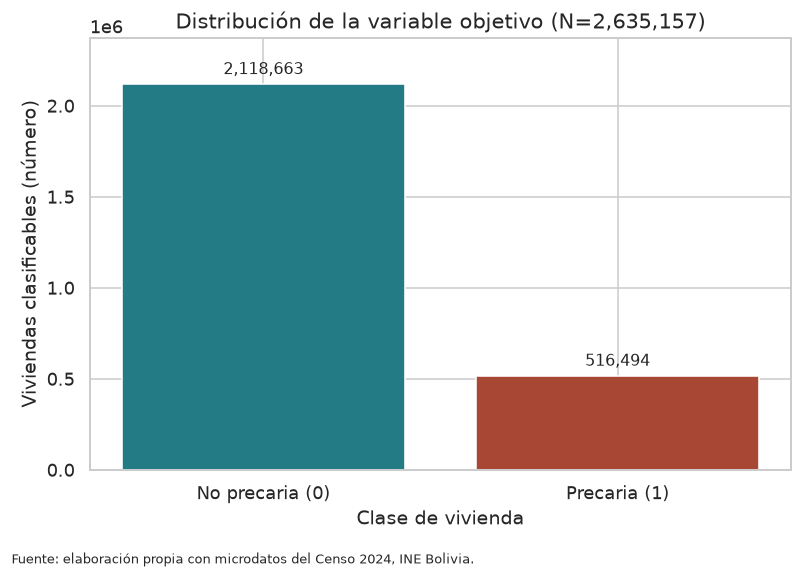

In [11]:
conteos = y.value_counts().reindex([0,1],fill_value=0)
fig,ax=plt.subplots(figsize=(7,5))
barras=ax.bar(["No precaria (0)","Precaria (1)"],conteos.values,color=["#237b86","#a94735"])
ax.bar_label(barras,labels=[f"{v:,}" for v in conteos.values],padding=4)
ax.set(title=f"Distribución de la variable objetivo (N={len(y):,})",
       xlabel="Clase de vivienda",ylabel="Viviendas clasificables (número)")
ax.set_ylim(0,max(conteos)*1.12)
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.04,1,1))
plt.show()

La clase precaria es minoritaria dentro de la población con objetivo. Por eso la exactitud global no basta para evaluar el modelo: también importa cuántas viviendas precarias detecta y cuántas clasifica incorrectamente como precarias.

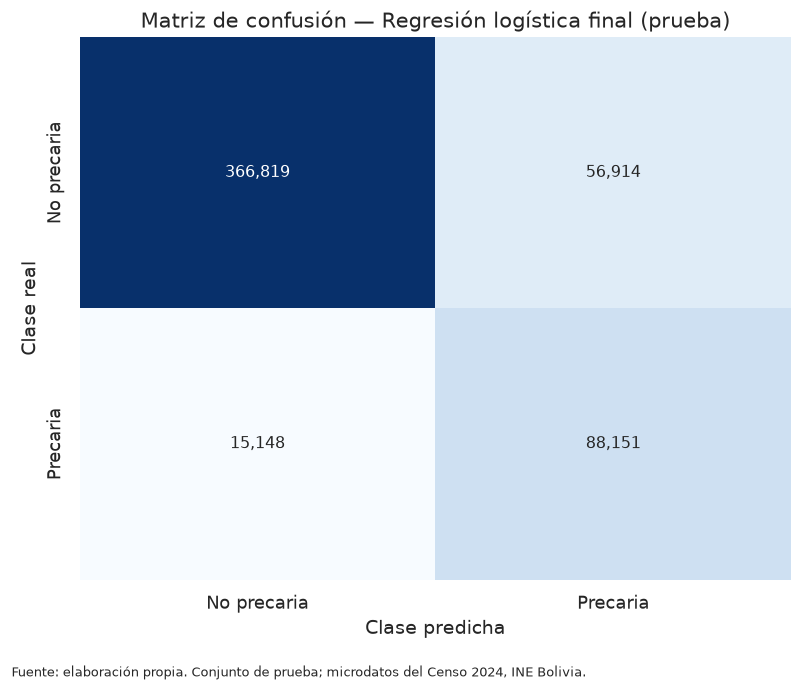

In [12]:
fig,ax=plt.subplots(figsize=(7,6))
sns.heatmap(cm_final,annot=True,fmt=",d",cmap="Blues",cbar=False,ax=ax,
            xticklabels=["No precaria","Precaria"],yticklabels=["No precaria","Precaria"])
ax.set(title="Matriz de confusión — Regresión logística final (prueba)",
       xlabel="Clase predicha",ylabel="Clase real")
fig.text(0.01,0.01,FUENTE_PRUEBA,fontsize=8)
fig.tight_layout(rect=(0,0.04,1,1))
plt.show()

Las filas de la matriz son clases reales y las columnas son clases predichas. La celda inferior izquierda contiene los falsos negativos: viviendas con dos o más carencias que el modelo clasificó como no precarias. La celda superior derecha contiene los falsos positivos.

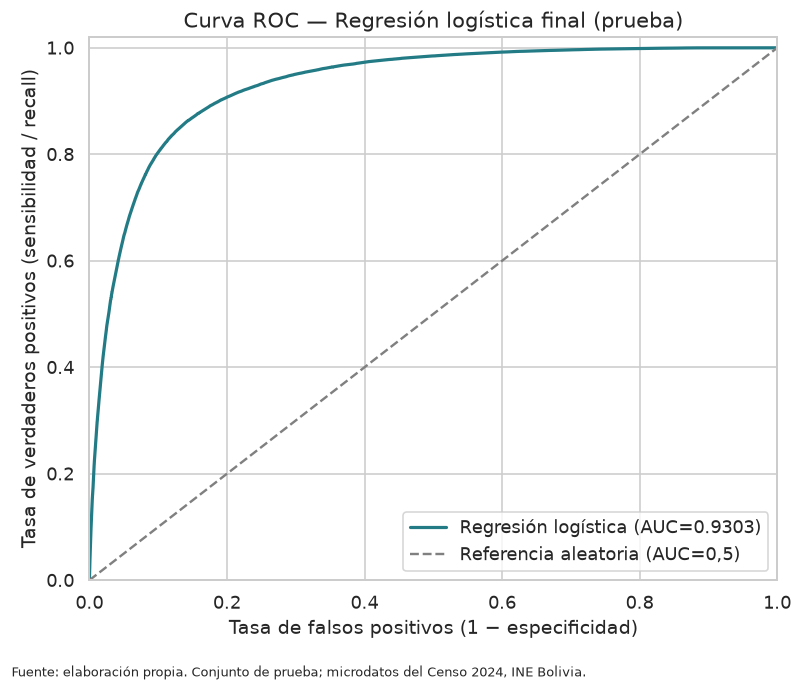

In [13]:
fpr,tpr,umbrales_roc = roc_curve(y_test,prob_final)
fig,ax=plt.subplots(figsize=(7,6))
ax.plot(fpr,tpr,color="#237b86",linewidth=2,
        label=f"Regresión logística (AUC={metricas_finales['ROC-AUC']:.4f})")
ax.plot([0,1],[0,1],linestyle="--",color="gray",label="Referencia aleatoria (AUC=0,5)")
ax.set(title="Curva ROC — Regresión logística final (prueba)",
       xlabel="Tasa de falsos positivos (1 − especificidad)",
       ylabel="Tasa de verdaderos positivos (sensibilidad / recall)",
       xlim=(0,1),ylim=(0,1.02))
ax.legend(loc="lower right")
fig.text(0.01,0.01,FUENTE_PRUEBA,fontsize=8)
fig.tight_layout(rect=(0,0.04,1,1))
plt.show()

La curva ROC muestra cómo cambian la detección de viviendas precarias y las falsas alarmas al variar el umbral. Su área se calcula con probabilidades de prueba; el punto correspondiente al umbral 0,5 es el usado para la matriz de confusión y las métricas de clasificación.

In [14]:
preparacion_final = modelo_final.named_steps["preprocesamiento"]
encoder_final = preparacion_final.named_transformers_["categoricas"]
nombres_transformados = preparacion_final.get_feature_names_out()
coeficientes = modelo_final.named_steps["clasificador"].coef_[0]
assert len(nombres_transformados)==len(coeficientes)

referencias = pd.DataFrame([{
    "Variable":col,"Código de referencia":str(categorias[0]),
    "Categoría oficial":fichas[col]["categorias"].get(str(categorias[0]),"Sin etiqueta")
} for col,categorias in zip(predictoras,encoder_final.categories_)])
display(referencias)

def describir_feature(nombre):
    sin_prefijo = nombre.removeprefix("categoricas__")
    for col in sorted(predictoras,key=len,reverse=True):
        prefijo=col+"_"
        if sin_prefijo.startswith(prefijo):
            codigo=sin_prefijo[len(prefijo):]
            etiqueta=fichas[col]["categorias"].get(codigo,"Sin etiqueta oficial")
            return col,codigo,etiqueta
    raise ValueError(f"Categoría transformada desconocida: {nombre}")

filas_coef=[]
for nombre,coef in zip(nombres_transformados,coeficientes):
    variable,codigo,etiqueta=describir_feature(nombre)
    filas_coef.append({"Variable/categoría":nombre,"Variable":variable,"Código":codigo,
                       "Categoría oficial":etiqueta,"Coeficiente":float(coef),
                       "Odds ratio":float(np.exp(coef))})
tabla_coef=pd.DataFrame(filas_coef)
print("Coeficientes positivos más altos:")
display(tabla_coef.nlargest(8,"Coeficiente").round(4))
print("Coeficientes negativos más bajos:")
display(tabla_coef.nsmallest(8,"Coeficiente").round(4))

,Variable,Código de referencia,Categoría oficial
0,urbrur,1,Urbana
1,v01_tipoviv,1,Casa
2,v03_pared,1,"Ladrillo, bloque de cemento, hormigón"
3,v05_techo,1,Calamina o plancha
4,v06_piso,1,Tierra
5,v11_basura,1,La depositan en el contenedor o basurero público
6,v13_habitac,1,Uno
7,v14_dormit,0,Cero
8,v17_tenencia,1,Propia y totalmente pagada
9,tip_hog,1,Hogar unipersonal


Coeficientes positivos más altos:


,Variable/categoría,Variable,Código,Categoría oficial,Coeficiente,Odds ratio
26,categoricas__v11_basura_4,v11_basura,4,La botan al río,1.5128,4.5392
28,categoricas__v11_basura_6,v11_basura,6,La entierran,1.3880,4.0070
3,categoricas__v01_tipoviv_4,v01_tipoviv,4,Cuarto(s) o habitación(es) suelta(s),1.3879,4.0064
27,categoricas__v11_basura_5,v11_basura,5,La queman,1.2338,3.4344
29,categoricas__v11_basura_7,v11_basura,7,Otra forma,1.1728,3.2309
25,categoricas__v11_basura_3,v11_basura,3,La botan en un terreno baldío o la calle,1.0905,2.9758
0,categoricas__urbrur_2,urbrur,2,Rural,0.9969,2.7099
5,categoricas__v01_tipoviv_6,v01_tipoviv,6,Establecimiento no destinado para vivienda,0.9148,2.4962


Coeficientes negativos más bajos:


,Variable/categoría,Variable,Código,Categoría oficial,Coeficiente,Odds ratio
2,categoricas__v01_tipoviv_3,v01_tipoviv,3,Departamento,-6.7103,0.0012
18,categoricas__v06_piso_4,v06_piso,4,"Cerámica, porcelanato",-1.7969,0.1658
17,categoricas__v06_piso_3,v06_piso,3,"Machimbre, parquet",-1.7902,0.1669
20,categoricas__v06_piso_6,v06_piso,6,"Mosaico, baldosa",-1.5901,0.2039
22,categoricas__v06_piso_8,v06_piso,8,Piso Flotante,-1.4888,0.2256
36,categoricas__v13_habitac_8,v13_habitac,8,Ocho o más,-1.2931,0.2744
35,categoricas__v13_habitac_7,v13_habitac,7,Siete,-1.2132,0.2973
19,categoricas__v06_piso_5,v06_piso,5,Cemento,-1.0762,0.3409


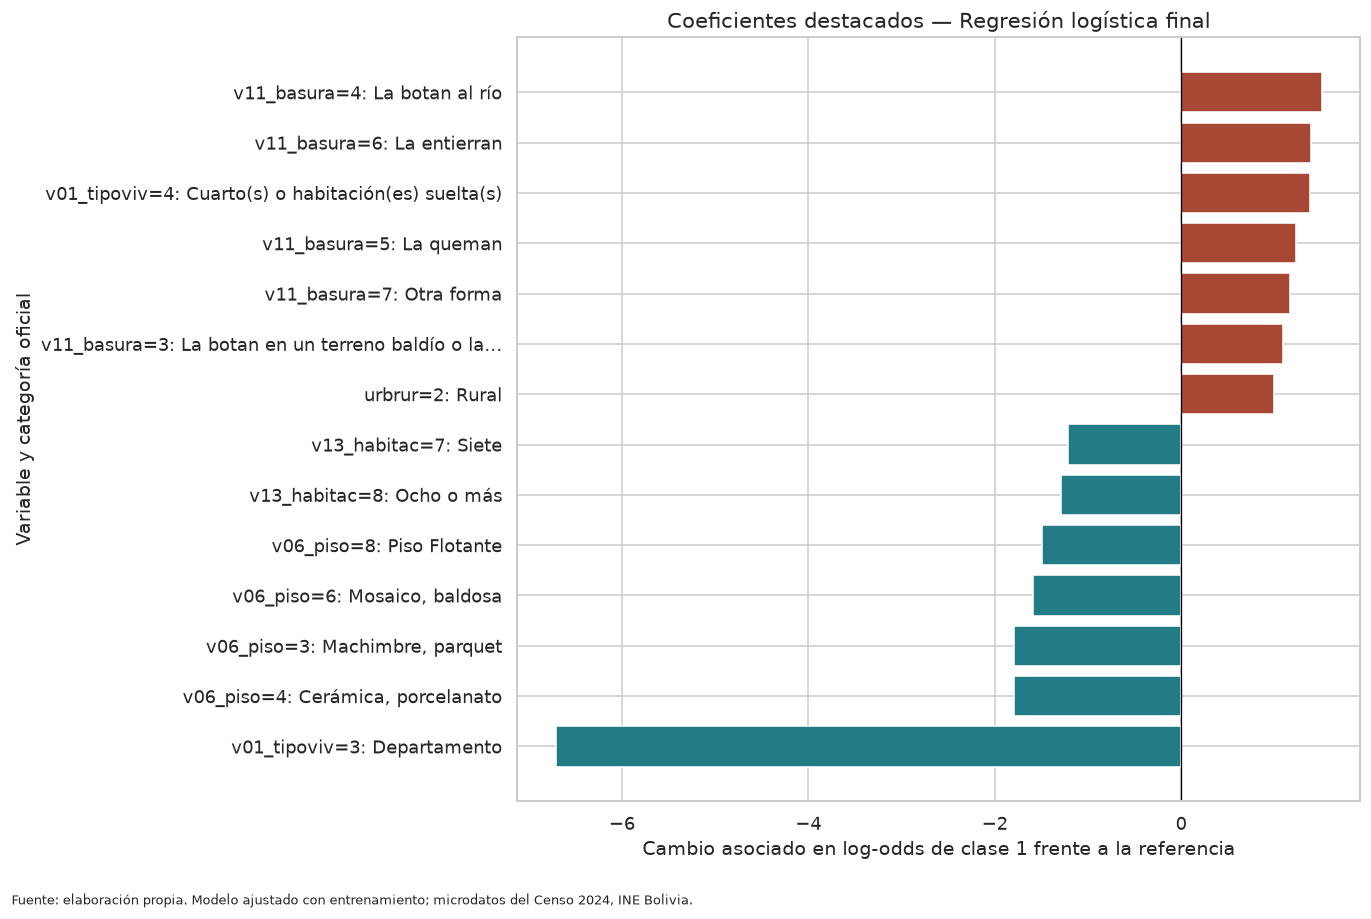

In [15]:
destacados=pd.concat([tabla_coef.nlargest(7,"Coeficiente"),
                         tabla_coef.nsmallest(7,"Coeficiente")]).drop_duplicates("Variable/categoría")
destacados=destacados.sort_values("Coeficiente")
etiquetas=[textwrap.shorten(f"{r['Variable']}={r['Código']}: {r['Categoría oficial']}",width=52,placeholder="…")
           for _,r in destacados.iterrows()]
fig,ax=plt.subplots(figsize=(12,8))
ax.barh(etiquetas,destacados["Coeficiente"],
        color=np.where(destacados["Coeficiente"]>=0,"#a94735","#237b86"))
ax.axvline(0,color="black",linewidth=0.8)
ax.set(title="Coeficientes destacados — Regresión logística final",
       xlabel="Cambio asociado en log-odds de clase 1 frente a la referencia",
       ylabel="Variable y categoría oficial")
fig.text(0.01,0.01,FUENTE_ENTRENAMIENTO,fontsize=8)
fig.tight_layout(rect=(0,0.04,1,1))
plt.show()

## 10. Interpretación de los coeficientes

La codificación One-Hot crea columnas para las categorías observadas y omite la primera categoría de cada variable como referencia. Un coeficiente positivo se asocia con mayores *log-odds* estimadas de clase 1, y uno negativo con menores *log-odds*, **comparado con la referencia y manteniendo los demás predictores constantes**. El *odds ratio* se obtiene con `exp(coeficiente)`. Estas relaciones no demuestran que una característica cause precariedad.

In [16]:
mayor_positivo=tabla_coef.loc[tabla_coef["Coeficiente"].idxmax()]
mayor_negativo=tabla_coef.loc[tabla_coef["Coeficiente"].idxmin()]
display(Markdown(
    f"El coeficiente positivo más alto corresponde a **{mayor_positivo['Variable']}={mayor_positivo['Código']} "
    f"({mayor_positivo['Categoría oficial']})**, con valor {mayor_positivo['Coeficiente']:+.4f} "
    f"y odds ratio {mayor_positivo['Odds ratio']:.4f}. El más negativo corresponde a "
    f"**{mayor_negativo['Variable']}={mayor_negativo['Código']} ({mayor_negativo['Categoría oficial']})**, "
    f"con valor {mayor_negativo['Coeficiente']:+.4f} y odds ratio {mayor_negativo['Odds ratio']:.4f}. "
    "Cada comparación se hace frente a la categoría omitida de esa variable; no representa un efecto causal."
))

El coeficiente positivo más alto corresponde a **v11_basura=4 (La botan al río)**, con valor +1.5128 y odds ratio 4.5392. El más negativo corresponde a **v01_tipoviv=3 (Departamento)**, con valor -6.7103 y odds ratio 0.0012. Cada comparación se hace frente a la categoría omitida de esa variable; no representa un efecto causal.

## 11. Aplicación al problema de investigación

El modelo asigna a cada vivienda clasificable una probabilidad estimada de clase 1. En una aplicación exploratoria, las viviendas con valores más altos podrían revisarse primero y sus resultados agregarse por área o clave territorial para localizar zonas que requieran estudio adicional. Esa agregación necesitaría informar tamaños de grupo y validarse antes de orientar intervenciones. Además, el uso de `class_weight="balanced"` puede afectar la calibración de las probabilidades: convendría comprobarla antes de interpretarlas como riesgos absolutos.

El **IPS** es un porcentaje descriptivo calculado a partir de carencias observadas entre viviendas válidas; una probabilidad del modelo es una **predicción** basada en otras características. Ninguna de las dos equivale por sí sola a una decisión pública o a una reducción efectiva de carencias. La partición aleatoria por vivienda tampoco demuestra que el modelo funcione igual en territorios no vistos.

## 12. Conclusiones

Las conclusiones siguientes se generan con las métricas de prueba de esta ejecución. La comparación con el modelo inicial es descriptiva: la elección de `C` se hizo antes, usando únicamente validación interna.

In [17]:
cambio_f1 = metricas_finales["F1"]-metricas_iniciales["F1"]
comparacion_texto = ("Se mantuvo el modelo inicial C=1: la mayor ganancia de F1 en validación fue "
                     f"{float(mejor_candidato['F1'])-f1_inicial:.6f}, inferior al mínimo de {UMBRAL_MEJORA_F1:.3f} fijado para cambiarlo."
                     if c_seleccionado==1.0 else
                     f"La validación interna seleccionó C={c_seleccionado:g} frente al C=1 inicial. "
                     f"En prueba, la diferencia descriptiva de F1 fue {cambio_f1:+.4f}; la prueba no intervino en la selección.")
display(Markdown(
    f"El modelo final obtuvo **accuracy {metricas_finales['Accuracy']:.4f}, precision {metricas_finales['Precision']:.4f}, "
    f"recall {metricas_finales['Recall']:.4f}, F1 {metricas_finales['F1']:.4f} y ROC-AUC "
    f"{metricas_finales['ROC-AUC']:.4f}** sobre {formato_entero(len(y_test))} viviendas de prueba. "
    f"{comparacion_texto} La regresión logística permite priorizar casos para revisión y estudiar asociaciones, "
    "pero el objetivo solo está definido para viviendas con cuatro dimensiones clasificables. "
    "La validación aleatoria no mide generalización a otros territorios o censos y las probabilidades no se calibraron. "
    "Como mejoras futuras, sería pertinente validar por territorios, examinar la sensibilidad de las reglas del IPS "
    "y comprobar la calibración antes de utilizar probabilidades en decisiones operativas."
))

El modelo final obtuvo **accuracy 0.8633, precision 0.6077, recall 0.8534, F1 0.7099 y ROC-AUC 0.9303** sobre 527.032 viviendas de prueba. Se mantuvo el modelo inicial C=1: la mayor ganancia de F1 en validación fue 0.000024, inferior al mínimo de 0.001 fijado para cambiarlo. La regresión logística permite priorizar casos para revisión y estudiar asociaciones, pero el objetivo solo está definido para viviendas con cuatro dimensiones clasificables. La validación aleatoria no mide generalización a otros territorios o censos y las probabilidades no se calibraron. Como mejoras futuras, sería pertinente validar por territorios, examinar la sensibilidad de las reglas del IPS y comprobar la calibración antes de utilizar probabilidades en decisiones operativas.

## 13. Fuente de los datos

**Instituto Nacional de Estadística (INE) de Bolivia.** Microdatos del Censo de Población y Vivienda 2024, archivo `Vivienda_CPV-2024.csv`, y `Diccionario de variables CPV 2024.xlsx`. Las reglas de población y carencia se reproducen de `entendimiento de datos.ipynb`; la configuración inicial de la regresión logística procede de `modelado_clasificacion.ipynb`. El IPS y la clase `vivienda_precaria` son construcciones metodológicas del proyecto, no indicadores oficiales del INE.